# Mother-Tongue Detector (母語偵測器)
### Telling Taiwanese Hokkien, Hakka and Mandarin apart, when off-the-shelf detectors can't

**Track:** AI + Languages

Taiwan has three big Chinese languages: **Mandarin** (華語), **Taiwanese Hokkien** (台語) and **Hakka** (客語).
All three are written with the same Chinese characters. A popular open-source detector (`langdetect`) calls about
half of our Hokkien and Hakka sentences **Korean** and most of the rest plain "Chinese". It even calls half of the
Mandarin sentences Korean. Every language tool (read-aloud, translation, search, spell-check) starts by asking "what
language is this?", so these languages get the wrong tool from step one.

This notebook builds a small, explainable model that answers that question, tests it fairly against simple
baselines, and shows where it fails.

**Run it yourself:** Runtime → Run all (about 5 minutes). It downloads all data from public sources.

## 1. Setup

In [1]:
%pip install -q opencc langdetect gradio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import bz2, csv, hashlib, json, os, re, sys, time, unicodedata, urllib.request
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import opencc
from langdetect import detect, DetectorFactory, LangDetectException

DetectorFactory.seed = 0          # makes langdetect give the same answer every run
pd.set_option("display.max_colwidth", 70)
os.makedirs("results", exist_ok=True); os.makedirs("models", exist_ok=True)

## 2. Data
Two public dictionaries from Taiwan's Ministry of Education (MOE). Every example sentence comes **with its Mandarin
translation**, so the model sees the *same meaning* in two languages. That stops it from cheating by learning topics
("farm words = Hakka") instead of the language itself.

| Source | What we use | Licence |
|---|---|---|
| [MOE Dictionary of Frequently-Used Taiwanese Hokkien](https://twblg.dict.edu.tw) (via [g0v/moedict-data-twblg](https://github.com/g0v/moedict-data-twblg)) | example sentences + Mandarin translations | CC BY-ND 3.0 TW |
| [MOE Dictionary of Frequently-Used Taiwan Hakka](https://hakkadict.moe.edu.tw) (via [g0v/moedict-data-hakka](https://github.com/g0v/moedict-data-hakka)) | example sentences + Mandarin translations | CC BY-ND 3.0 TW |
| [Tatoeba](https://tatoeba.org/en/downloads) | sentences written by volunteers: an **outside test** (sections 6–7), then Cantonese and extra Mandarin for the improved model (section 9) | CC BY 2.0 FR |

We download the files at run time and don't redistribute them.

In [3]:
RAW = "data/raw"
os.makedirs(RAW, exist_ok=True)
SOURCES = {
    "twblg_examples.csv": "https://raw.githubusercontent.com/g0v/moedict-data-twblg/master/uni/%E4%BE%8B%E5%8F%A5.csv",
    "dict-hakka.json":    "https://raw.githubusercontent.com/g0v/moedict-data-hakka/master/dict-hakka.json",
}
for lang in ["cmn", "yue", "nan", "hak"]:
    SOURCES[f"tatoeba_{lang}.tsv"] = f"https://downloads.tatoeba.org/exports/per_language/{lang}/{lang}_sentences.tsv.bz2"

for name, url in SOURCES.items():
    path = os.path.join(RAW, name)
    if not os.path.exists(path):
        data = urllib.request.urlopen(url, timeout=120).read()
        if url.endswith(".bz2"):
            data = bz2.decompress(data)
        with open(path, "wb") as f:
            f.write(data)
    print(f"{name:22s} {os.path.getsize(path) / 1e6:6.2f} MB")

twblg_examples.csv       1.76 MB
dict-hakka.json          9.87 MB
tatoeba_cmn.tsv          4.25 MB
tatoeba_yue.tsv          5.19 MB
tatoeba_nan.tsv          0.02 MB
tatoeba_hak.tsv          0.00 MB


### Cleaning
* Keep **only Chinese characters**. Punctuation, spaces and Latin letters differ between sources, and a model could
  learn those differences instead of the language.
* `NFKC` normalisation turns look-alike symbols into normal characters (for example the radical `⼀` into `一`).
* Drop sentences with characters that have no standard code (the dictionaries show them as `□` or private-use symbols).

In [4]:
HAN = re.compile(r"[㐀-䶿一-鿿豈-﫿\U00020000-\U0003134F]")   # Chinese characters
BAD = re.compile(r"[-\U000F0000-\U0010FFFF□]")                         # private-use symbols and the box

def clean(text):
    """Keep only the Chinese characters of a sentence."""
    return "".join(HAN.findall(unicodedata.normalize("NFKC", text)))

rows = []   # (original sentence, language, source, group). A group is one dictionary entry.
with open(f"{RAW}/twblg_examples.csv", encoding="utf-8") as f:
    for r in csv.DictReader(f):
        group = "hokkien-dict/" + r["主編碼"]
        rows.append((r["例句"], "Taiwanese Hokkien", "MOE Hokkien dictionary", group))
        rows.append((r["華語翻譯"], "Mandarin", "MOE Hokkien dictionary", group))

PAIR = re.compile("￹([^￹￻]*)￻([^￹]*)")    # the Hakka file stores "￹Hakka sentence￻Mandarin translation"
for entry in json.load(open(f"{RAW}/dict-hakka.json", encoding="utf-8")):
    group = "hakka-dict/" + entry["title"]
    for h in entry.get("heteronyms", []):
        for d in h.get("definitions", []):
            for ex in d.get("example", []):
                for hakka, mandarin in PAIR.findall(ex):
                    rows.append((hakka, "Hakka", "MOE Hakka dictionary", group))
                    rows.append((mandarin, "Mandarin", "MOE Hakka dictionary", group))

raw = pd.DataFrame(rows, columns=["sentence", "language", "source", "group"])
raw = raw[~raw.sentence.map(lambda s: bool(BAD.search(s)))].copy()
raw["text"] = raw.sentence.map(clean)
raw = raw[raw.text.str.len() >= 2]

# A text that appears in two languages (e.g. 了解 is both Mandarin and Hokkien) can't be labelled. Drop it everywhere.
n_langs = raw.groupby("text").language.nunique()
ambiguous = set(n_langs[n_langs > 1].index)
df = raw[~raw.text.isin(ambiguous)].drop_duplicates(subset="text").reset_index(drop=True)
print(f"{len(rows):,} raw sentences -> {len(df):,} usable unique sentences "
      f"({len(ambiguous):,} texts dropped because they appear in more than one language)")
df.groupby(["source", "language"]).size().rename("sentences").to_frame()

72,478 raw sentences -> 58,845 usable unique sentences (979 texts dropped because they appear in more than one language)


sentences
source                 language                    
MOE Hakka dictionary   Hakka                  18705
                       Mandarin               12438
MOE Hokkien dictionary Mandarin               12742
                       Taiwanese Hokkien      14960

In [5]:
# The same meaning in two languages (one entry from each dictionary)
for g in ["hokkien-dict/2", "hakka-dict/□儕"] + list(df[df.language == "Hakka"].group.sample(1, random_state=3)):
    print(df[df.group == g][["sentence", "language"]].head(2).to_string(index=False, header=False), "\n")

        一流 Taiwanese Hokkien
𪜶兩个生做一模一樣。 Taiwanese Hokkien 

今天有好幾個人來問考試的事情，這件事需要對學生說清楚些。 Mandarin 

  拜託你摎這兜無愛个東西拿去㧒忒，莫歸間屋堆到像垃圾堆共樣！    Hakka
拜託你把這些不要的東西拿去扔掉，不要整間屋子堆得像垃圾堆一樣！ Mandarin 



### Train / validation / test split
We split by **dictionary entry**, not by sentence. A Hokkien sentence and its Mandarin translation always land in the
same split, and so do all examples of one word, so the test set really is unseen.
70% train, 15% validation (for choosing settings), 15% test (used once, at the end).

In [6]:
def split_of(group):
    bucket = int(hashlib.md5(group.encode("utf-8")).hexdigest(), 16) % 100
    return "train" if bucket < 70 else "val" if bucket < 85 else "test"

df["split"] = df.group.map(split_of)
LANGS = ["Mandarin", "Taiwanese Hokkien", "Hakka"]
train, val, test = (df[df.split == s] for s in ["train", "val", "test"])
pd.crosstab(df.language, df.split)[["train", "val", "test"]]

split,train,val,test
language,,,
Hakka,12960,2788,2957
Mandarin,17617,3703,3860
Taiwanese Hokkien,10483,2153,2324


## 3. Baselines
1. **Always Mandarin**: the most common answer.
2. **langdetect**: a popular open-source detector (55 languages). It has no Hokkien or Hakka, so the best it can do
   is say "Chinese"; we count any Chinese answer as Mandarin.
3. **Unique-character rule**: a simple rule with no machine learning. Find characters that appear in only one
   language in the training data (at least 3 times), then let each such character vote.

In [7]:
def scores(name, y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    out = {"method": name,
           "accuracy": accuracy_score(y_true, y_pred),
           "macro F1": f1_score(y_true, y_pred, labels=LANGS, average="macro", zero_division=0)}
    for lang in LANGS:
        out[f"recall {lang}"] = (y_pred[y_true == lang] == lang).mean()
    return out

# 1) always the most common class
majority = train.language.value_counts().idxmax()
pred_majority = [majority] * len(test)

# 2) langdetect, on the original sentence with punctuation (the fairest input for it)
def langdetect_code(sentence):
    try:
        return detect(sentence)
    except LangDetectException:
        return "none"
t0 = time.time()
test = test.assign(langdetect=test.sentence.map(langdetect_code))
pred_langdetect = ["Mandarin" if c.startswith("zh") else c for c in test.langdetect]
print(f"langdetect took {time.time() - t0:.0f} s")

# 3) unique-character vote
char_langs = defaultdict(Counter)
for text, lang in zip(train.text, train.language):
    for ch in set(text):
        char_langs[ch][lang] += 1
unique_char = {ch: next(iter(c)) for ch, c in char_langs.items() if len(c) == 1 and sum(c.values()) >= 3}
def rule_predict(text):
    votes = Counter(unique_char[ch] for ch in text if ch in unique_char)
    return votes.most_common(1)[0][0] if votes else majority
pred_rule = [rule_predict(t) for t in test.text]
print(f"{len(unique_char):,} characters appear in only one language, e.g.",
      {lang: "".join([ch for ch, l in unique_char.items() if l == lang][:12]) for lang in LANGS})

langdetect took 15 s
575 characters appear in only one language, e.g. {'Mandarin': '朵們髒很她它砍什丐掐脖狠', 'Taiwanese Hokkien': '𪜶偌𠢕厝阮佮尻暝囡䆀囝媠', 'Hakka': '㐁忒㓾痢㜮磡摎㧡厥粢扡粑'}


In [8]:
# What does langdetect think Hokkien and Hakka are?
names = {"ko": "Korean", "zh-tw": "Chinese (Taiwan)", "zh-cn": "Chinese (China)", "ja": "Japanese", "vi": "Vietnamese"}
ld = (test.assign(answer=test.langdetect.map(lambda c: names.get(c, c)))
          .groupby("language").answer.value_counts(normalize=True).mul(100).round(1)
          .rename("% of test sentences").reset_index())
ld.groupby("language").head(3)

,language,answer,% of test sentences
0,Hakka,Korean,43.6
1,Hakka,Chinese (Taiwan),33.3
2,Hakka,Chinese (China),17.0
9,Mandarin,Korean,49.0
10,Mandarin,Chinese (Taiwan),39.2
11,Mandarin,Chinese (China),11.6
14,Taiwanese Hokkien,Korean,49.2
15,Taiwanese Hokkien,Chinese (Taiwan),31.2
16,Taiwanese Hokkien,Chinese (China),19.2


## 4. Our model
Each sentence becomes a bag of **character n-grams**: single characters, pairs and triples, weighted by TF-IDF
(common everywhere = less weight). A **logistic regression** learns how much each n-gram points to each language.
It trains in seconds, and we can read off exactly which characters drove each decision.

We pick the n-gram range and regularisation strength `C` on the **validation** set only.

In [9]:
def make_model(ngram=(1, 3), C=10):
    return make_pipeline(
        TfidfVectorizer(analyzer="char", ngram_range=ngram, sublinear_tf=True, min_df=2),
        LogisticRegression(C=C, max_iter=3000))

tuning = []
for ngram in [(1, 1), (1, 2), (1, 3)]:
    for C in [3, 30]:
        t0 = time.time()
        m = make_model(ngram, C).fit(train.text, train.language)
        tuning.append({"ngram": ngram, "C": C,
                       "val macro F1": f1_score(val.language, m.predict(val.text), average="macro"),
                       "seconds": round(time.time() - t0, 1)})
tuning = pd.DataFrame(tuning).sort_values("val macro F1", ascending=False)
best = tuning.iloc[0]
print("best settings:", best.ngram, "C =", best.C)
tuning

best settings: (1, 2) C = 3


,ngram,C,val macro F1,seconds
2,"(1, 2)",3,0.861372,1.6
4,"(1, 3)",3,0.860062,2.9
5,"(1, 3)",30,0.853433,3.6
3,"(1, 2)",30,0.851727,2.0
0,"(1, 1)",3,0.844712,0.8
1,"(1, 1)",30,0.835432,1.0


In [10]:
# Final model: train on train + validation with the best settings, then score the test set ONCE.
model = make_model(best.ngram, best.C).fit(pd.concat([train.text, val.text]), pd.concat([train.language, val.language]))
proba = model.predict_proba(test.text)
classes = list(model.classes_)
test = test.assign(pred=[classes[i] for i in proba.argmax(1)], confidence=proba.max(1))

results = pd.DataFrame([scores("Always Mandarin", test.language, pred_majority),
                        scores("langdetect (off-the-shelf)", test.language, pred_langdetect),
                        scores("Unique-character rule", test.language, pred_rule),
                        scores("Our model (char n-grams + logistic regression)", test.language, test.pred)])
results.to_csv("results/test_scores.csv", index=False)
results.style.format({c: "{:.1%}" for c in results.columns if c != "method"}).hide(axis="index")

method,accuracy,macro F1,recall Mandarin,recall Taiwanese Hokkien,recall Hakka
Always Mandarin,42.2%,19.8%,100.0%,0.0%,0.0%
langdetect (off-the-shelf),21.4%,15.4%,50.8%,0.0%,0.0%
Unique-character rule,54.9%,45.8%,99.8%,22.4%,21.7%
Our model (char n-grams + logistic regression),85.7%,84.6%,92.9%,79.0%,81.6%


accuracy on test texts with 4+ characters: 94.5% (7,159 texts)
accuracy on test texts with 7+ characters: 97.9% (6,150 texts)
                   precision    recall  f1-score   support

            Hakka      0.820     0.816     0.818      2957
         Mandarin      0.917     0.929     0.923      3860
Taiwanese Hokkien      0.802     0.790     0.796      2324

         accuracy                          0.857      9141
        macro avg      0.846     0.845     0.846      9141
     weighted avg      0.857     0.857     0.857      9141



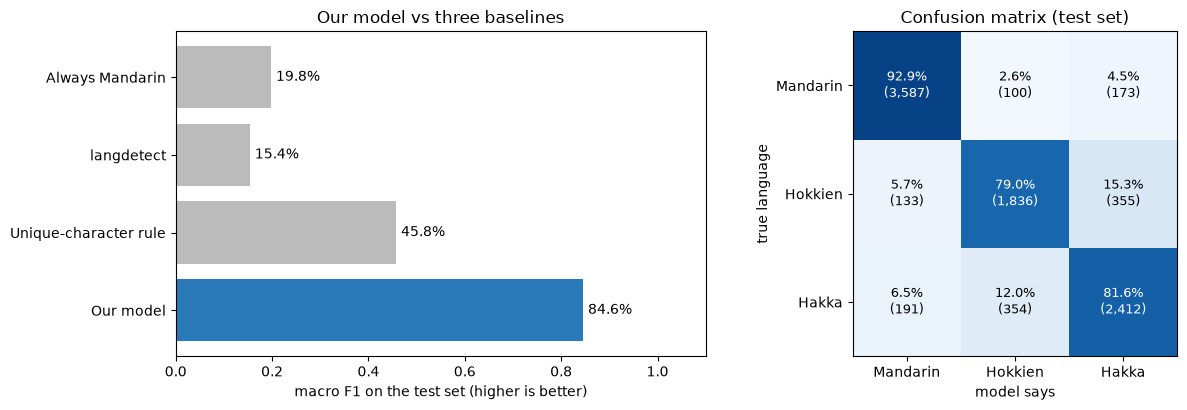

In [11]:
for k in [4, 7]:
    d = test[test.text.str.len() >= k]
    print(f"accuracy on test texts with {k}+ characters: {(d.pred == d.language).mean():.1%} ({len(d):,} texts)")
print(classification_report(test.language, test.pred, digits=3))
cm = confusion_matrix(test.language, test.pred, labels=LANGS)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
r = results.set_index("method")["macro F1"]
ax.barh(["Always Mandarin", "langdetect", "Unique-character rule", "Our model"], r.values,
        color=["#bbb", "#bbb", "#bbb", "#2a7ab9"])
for i, v in enumerate(r.values):
    ax.text(v + 0.01, i, f"{v:.1%}", va="center")
ax.set_xlim(0, 1.1); ax.set_xlabel("macro F1 on the test set (higher is better)"); ax.invert_yaxis()
ax.set_title("Our model vs three baselines")
ax = axes[1]
pct = cm / cm.sum(1, keepdims=True)
ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
short = ["Mandarin", "Hokkien", "Hakka"]
ax.set_xticks(range(3), short); ax.set_yticks(range(3), short)
ax.set_xlabel("model says"); ax.set_ylabel("true language")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{pct[i, j]:.1%}\n({cm[i, j]:,})", ha="center", va="center",
                color="white" if pct[i, j] > 0.5 else "black", fontsize=9)
ax.set_title("Confusion matrix (test set)")
plt.tight_layout(); plt.savefig("results/scores_and_confusion.png", dpi=150); plt.show()

## 5. Where it fails
### Short texts
Fewer characters means fewer clues. We group test sentences by length.

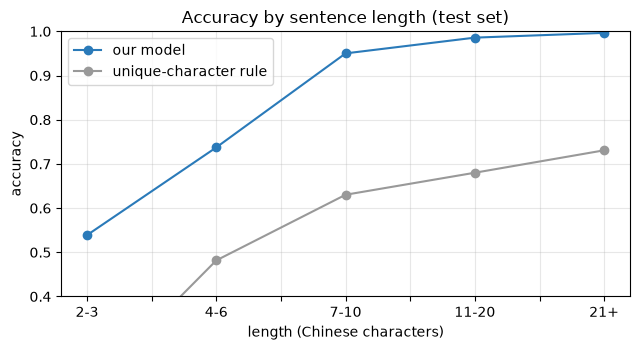

,sentences,our model,unique-character rule
length,,,
2-3,"1,982",53.9%,18.7%
4-6,"1,009",73.7%,48.2%
7-10,"1,363",95.0%,63.0%
11-20,"3,929",98.6%,68.0%
21+,858,99.7%,73.1%


In [12]:
bins = [2, 4, 7, 11, 21, 999]
labels = ["2-3", "4-6", "7-10", "11-20", "21+"]
test = test.assign(length=pd.cut(test.text.str.len(), bins=bins, right=False, labels=labels),
                   rule=pred_rule, correct=lambda d: d.pred == d.language)
by_len = test.groupby("length", observed=True).apply(
    lambda d: pd.Series({"sentences": len(d), "our model": (d.pred == d.language).mean(),
                         "unique-character rule": (d.rule == d.language).mean()}), include_groups=False)
ax = by_len[["our model", "unique-character rule"]].plot(marker="o", figsize=(6.5, 3.6), color=["#2a7ab9", "#999"])
ax.set_ylim(0.4, 1.0); ax.set_ylabel("accuracy"); ax.set_xlabel("length (Chinese characters)")
ax.set_title("Accuracy by sentence length (test set)"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("results/accuracy_by_length.png", dpi=150); plt.show()
by_len.style.format({"sentences": "{:,.0f}", "our model": "{:.1%}", "unique-character rule": "{:.1%}"})

### Real mistakes, next to the right answer

In [13]:
wrong = test[~test.correct & (test.text.str.len() >= 6)].sample(12, random_state=1)
wrong[["sentence", "language", "pred", "confidence"]].rename(
    columns={"language": "true language", "pred": "model said"}).style.format({"confidence": "{:.0%}"}).hide(axis="index")

sentence,true language,model said,confidence
霜風一直對門縫貫入來。,Taiwanese Hokkien,Mandarin,40%
老人家無理取鬧,Mandarin,Hakka,69%
拳頭對著胸部重擊下去。,Mandarin,Hakka,62%
覺悟著過去做了毋著。,Taiwanese Hokkien,Hakka,90%
這個計畫頂頭批准通過，做得開始進行了。,Hakka,Mandarin,63%
只要有你，代誌就會成功。,Taiwanese Hokkien,Mandarin,56%
照慣例，比賽開始以前，雙方選手愛互相行禮。,Hakka,Mandarin,50%
食苦當做食補。,Taiwanese Hokkien,Hakka,58%
規間店的泡麵掃了了。,Taiwanese Hokkien,Mandarin,79%
生癬愛去看皮膚科。,Taiwanese Hokkien,Hakka,51%


### What the model learned
The n-grams that push hardest towards each language. Many are **grammar words**, the small words every sentence needs:

In [14]:
vec = model.named_steps["tfidfvectorizer"]
clf = model.named_steps["logisticregression"]
vocab = np.array(vec.get_feature_names_out())
rel = clf.coef_ - clf.coef_.mean(0)          # evidence for each language relative to the others
top = {lang: list(vocab[np.argsort(-rel[k])[:20]]) for k, lang in enumerate(clf.classes_)}
pd.DataFrame(top)[LANGS]

,Mandarin,Taiwanese Hokkien,Hakka
0,的,伊,个
1,他,矣,佢
2,很,袂,係
3,要,咧,摎
4,不,予,忒
5,吃,攏,毋
6,沒,欲,𠊎
7,是,跤,做得
8,了,仔,該
9,子,毋通,恁


## 6. Does it work on text from somewhere else?
So far the test sentences came from the same two dictionaries as the training sentences. Real messages won't.
[Tatoeba](https://tatoeba.org) sentences are written by volunteers, so they're a fair outside test.
* **Mandarin:** 2,000 random Tatoeba sentences already written in Traditional characters.
* **Taiwanese Hokkien:** every Tatoeba Hokkien (`nan`) sentence written in Chinese characters.
* **Hakka:** every Tatoeba Hakka (`hak`) sentence with Chinese characters. Most are written in Simplified characters,
  so we convert them to Traditional with OpenCC. We keep `个`, because Hakka uses it as a grammar word.

In [15]:
s2t = opencc.OpenCC("s2t")
def to_traditional(sentence):
    return s2t.convert(sentence.replace("个", "\u0001")).replace("\u0001", "个")

def load_tatoeba(code_):
    rows = []
    with open(f"{RAW}/tatoeba_{code_}.tsv", encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t")
            if len(parts) >= 3:
                rows.append((parts[0], parts[2]))
    return pd.DataFrame(rows, columns=["id", "sentence"])

tat = []
cmn = load_tatoeba("cmn")
cmn = cmn[cmn.sentence.map(lambda s: s2t.convert(s) == s)].sample(2000, random_state=0)
tat.append(cmn.assign(language="Mandarin"))
tat.append(load_tatoeba("nan").assign(language="Taiwanese Hokkien"))
hak = load_tatoeba("hak"); hak["sentence"] = hak.sentence.map(to_traditional)
tat.append(hak.assign(language="Hakka"))
tat = pd.concat(tat, ignore_index=True)
tat["text"] = tat.sentence.map(clean)
tat = tat[tat.text.str.len() >= 2].reset_index(drop=True)

p = model.predict_proba(tat.text)
tat["pred"] = [classes[i] for i in p.argmax(1)]
tat["confidence"] = p.max(1)
tat["langdetect"] = ["Mandarin" if c.startswith("zh") else c for c in tat.sentence.map(langdetect_code)]
outside = tat.groupby("language").apply(lambda d: pd.Series({
    "sentences": len(d), "our model": (d.pred == d.name).mean(),
    "langdetect": (d.langdetect == d.name).mean()}), include_groups=False).loc[LANGS]
outside.style.format({"sentences": "{:,.0f}", "our model": "{:.1%}", "langdetect": "{:.1%}"})

,sentences,our model,langdetect
language,,,
Mandarin,"1,993",93.7%,49.0%
Taiwanese Hokkien,297,59.9%,0.0%
Hakka,64,62.5%,0.0%


In [16]:
tat[(tat.pred != tat.language)].groupby("language").head(4)[["sentence", "language", "pred", "confidence"]].rename(
    columns={"language": "true language", "pred": "model said"}).style.format({"confidence": "{:.0%}"}).hide(axis="index")

sentence,true language,model said,confidence
湯姆缺席。,Mandarin,Hakka,88%
抗議。,Mandarin,Hakka,67%
啊哦。,Mandarin,Hakka,93%
咖啡好了。,Mandarin,Hakka,58%
汝可用任一種汝想欲个語言來寫。着 Taboeba，所有个語言做蜀是平样个。,Taiwanese Hokkien,Hakka,80%
好孬？,Taiwanese Hokkien,Hakka,47%
哈哈。,Taiwanese Hokkien,Hakka,75%
翻譯下。,Taiwanese Hokkien,Hakka,78%
我愛爾。,Hakka,Taiwanese Hokkien,95%
Tom思念你。,Hakka,Taiwanese Hokkien,76%


## 7. A language it has never seen: Cantonese
A real inbox also gets languages the model was never trained on. Cantonese (粵語) is the hardest look-alike: it is
written with the same characters, and it shares some grammar words with Hakka. What does our 3-language model do?

In [17]:
yue = load_tatoeba("yue")
yue = yue[yue.sentence.map(lambda s: s2t.convert(s) == s)].sample(2000, random_state=0)
yue["text"] = yue.sentence.map(clean)
p = model.predict_proba(yue.text)
yue["pred"] = [classes[i] for i in p.argmax(1)]
yue["confidence"] = p.max(1)
print("Cantonese sentences labelled as:")
print((yue.pred.value_counts(normalize=True) * 100).round(1).to_string())
print(f"\nMedian confidence on Cantonese: {yue.confidence.median():.0%}  "
      f"(on the real test set: {test.confidence.median():.0%})")

Cantonese sentences labelled as:
pred
Mandarin             65.0
Hakka                29.0
Taiwanese Hokkien     5.9

Median confidence on Cantonese: 83%  (on the real test set: 97%)


## 8. Saying "not sure"
A wrong answer said confidently is worse than "not sure". We add a rule: if the top probability is below a threshold,
the tool answers **not sure** and asks for a human. We choose the threshold on the **validation** set so the tool still
answers at least 95% of real Mandarin, Hokkien and Hakka sentences.

In [18]:
# Probabilities on the validation set, from a model trained on train only (the test set stays untouched).
m_train = make_model(best.ngram, best.C).fit(train.text, train.language)
val_conf = m_train.predict_proba(val.text).max(1)
THRESHOLD = float(np.quantile(val_conf, 0.05))     # 95% of validation sentences are at or above this
print(f"threshold = {THRESHOLD:.2f}")

answered = test.confidence >= THRESHOLD
print(f"Test set: answers {answered.mean():.1%} of sentences; accuracy on those it answers: "
      f"{(test.pred == test.language)[answered].mean():.1%} (vs {(test.pred == test.language).mean():.1%} if it must answer all)")
print(f"Cantonese: says 'not sure' for {(yue.confidence < THRESHOLD).mean():.1%} of sentences")

threshold = 0.48
Test set: answers 94.0% of sentences; accuracy on those it answers: 88.4% (vs 85.7% if it must answer all)
Cantonese: says 'not sure' for 3.5% of sentences


## 9. Improvement: teach it Cantonese
The "not sure" rule barely helps with Cantonese, because the model is wrong *and confident*. So we add Cantonese as a
fourth language, using Tatoeba sentences already written in Traditional characters.

**A trap we avoid:** all our Cantonese comes from Tatoeba. If Tatoeba only ever meant "Cantonese", the model could
learn "short, chatty Tatoeba sentence = Cantonese" instead of learning Cantonese. So we also add Tatoeba **Mandarin**
sentences to training. Tatoeba sentences are split 70/15/15 by sentence ID, and the Tatoeba Hokkien and Hakka
sentences stay out of training completely, so they remain a pure outside test.

**A second change, from section 5:** with fewer than 4 characters the model is barely better than a guess, so the
tool now answers "too short to tell" instead of guessing.

In [19]:
LANGS4 = LANGS + ["Cantonese"]
MIN_CHARS = 4

def tatoeba_traditional(code_, language):
    t = load_tatoeba(code_)
    t = t[t.sentence.map(lambda s: s2t.convert(s) == s)].assign(language=language, source="Tatoeba")
    t["text"] = t.sentence.map(clean)
    t["split"] = t.id.map(lambda i: split_of("tatoeba/" + i))
    return t[t.text.str.len() >= 2]

extra = pd.concat([tatoeba_traditional("yue", "Cantonese"),
                   tatoeba_traditional("cmn", "Mandarin").sample(15000, random_state=1)])
extra = extra[~extra.text.isin(set(df.text))].drop_duplicates(subset="text")
both = pd.concat([df, extra], ignore_index=True)
print(pd.crosstab([both.source.where(both.source == "Tatoeba", "MOE dictionaries"), both.language], both.split)[["train", "val", "test"]])

fit_rows = both[both.split.isin(["train", "val"])]
model4 = make_model(best.ngram, best.C).fit(fit_rows.text, fit_rows.language)
classes4 = list(model4.classes_)

# "Not sure" threshold for the new model, chosen on validation sentences with 4+ characters (model trained on train only)
m4_train = make_model(best.ngram, best.C).fit(both[both.split == "train"].text, both[both.split == "train"].language)
v = both[(both.split == "val") & (both.text.str.len() >= MIN_CHARS)]
THRESHOLD4 = float(np.quantile(m4_train.predict_proba(v.text).max(1), 0.05))
print(f"\nnot-sure threshold for the 4-language model: {THRESHOLD4:.2f}")

split                               train   val  test
source           language                            
MOE dictionaries Hakka              12960  2788  2957
                 Mandarin           17617  3703  3860
                 Taiwanese Hokkien  10483  2153  2324
Tatoeba          Cantonese          11971  2670  2479
                 Mandarin           10392  2206  2280



not-sure threshold for the 4-language model: 0.58


In [20]:
def accuracy_on(m, data, min_chars=0):
    d = data[data.text.str.len() >= min_chars]
    return (m.predict(d.text) == d.language).mean(), len(d)

tat_test = pd.concat([
    both[(both.source == "Tatoeba") & (both.split == "test") & (both.language == "Mandarin")],
    tat[tat.language.isin(["Taiwanese Hokkien", "Hakka"])],
    both[(both.source == "Tatoeba") & (both.split == "test") & (both.language == "Cantonese")]])
moe_test = both[(both.source != "Tatoeba") & (both.split == "test")]

rows = []
for name, data, min_chars in [("MOE test, all lengths", moe_test, 0),
                              ("MOE test, 4+ characters", moe_test, MIN_CHARS)] + \
        [(f"Tatoeba {l}, 4+ characters", tat_test[tat_test.language == l], MIN_CHARS) for l in LANGS4]:
    a3, n = accuracy_on(model, data, min_chars)
    a4, _ = accuracy_on(model4, data, min_chars)
    rows.append({"test set": name, "sentences": n, "3-language model": a3, "4-language model": a4})
compare = pd.DataFrame(rows)
compare.to_csv("results/improvement_cantonese.csv", index=False)
compare.style.format({"sentences": "{:,.0f}", "3-language model": "{:.1%}", "4-language model": "{:.1%}"}).hide(axis="index")

test set,sentences,3-language model,4-language model
"MOE test, all lengths","9,141",85.7%,85.3%
"MOE test, 4+ characters","7,159",94.5%,94.4%
"Tatoeba Mandarin, 4+ characters","2,198",93.4%,97.7%
"Tatoeba Taiwanese Hokkien, 4+ characters",125,92.0%,89.6%
"Tatoeba Hakka, 4+ characters",61,63.9%,37.7%
"Tatoeba Cantonese, 4+ characters","2,460",0.0%,97.1%


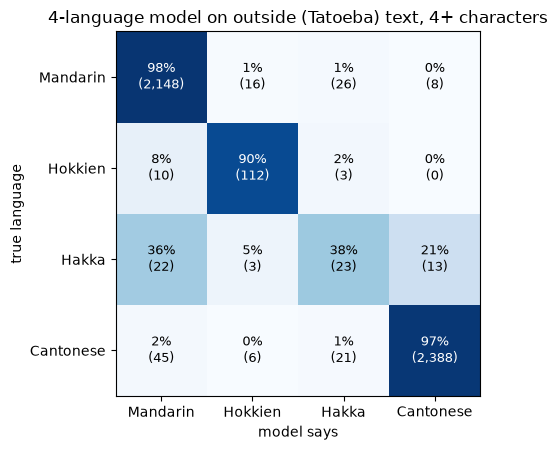

In [21]:
t4 = tat_test[tat_test.text.str.len() >= MIN_CHARS]
p4 = model4.predict(t4.text)
cm4 = confusion_matrix(t4.language, p4, labels=LANGS4)
pct4 = cm4 / cm4.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.imshow(pct4, cmap="Blues", vmin=0, vmax=1)
short4 = ["Mandarin", "Hokkien", "Hakka", "Cantonese"]
ax.set_xticks(range(4), short4); ax.set_yticks(range(4), short4)
ax.set_xlabel("model says"); ax.set_ylabel("true language")
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{pct4[i, j]:.0%}\n({cm4[i, j]:,})", ha="center", va="center",
                color="white" if pct4[i, j] > 0.5 else "black", fontsize=9)
ax.set_title("4-language model on outside (Tatoeba) text, 4+ characters")
plt.tight_layout(); plt.savefig("results/confusion_outside_4lang.png", dpi=150); plt.show()

## 10. Try it
In Colab this opens a small app. Type or paste a sentence and the tool shows its guess, how sure it is, and which
characters pushed it towards that language.

In [22]:
import gradio as gr

def char_evidence(m, text, lang):
    """How much each character pushed model `m` towards `lang` (positive) or away from it (negative)."""
    v, c = m.named_steps["tfidfvectorizer"], m.named_steps["logisticregression"]
    k = list(c.classes_).index(lang)
    x = v.transform([text])
    lo, hi = v.ngram_range
    grams = [(i, n, text[i:i + n]) for n in range(lo, hi + 1) for i in range(len(text) - n + 1)]
    counts = Counter(g for _, _, g in grams)
    score = np.zeros(len(text))
    for i, n, g in grams:
        j = v.vocabulary_.get(g)
        if j is not None:
            weight = c.coef_[k, j] - c.coef_[:, j].mean()
            score[i:i + n] += x[0, j] * weight / counts[g] / n
    return score

def detect_language(sentence):
    text = clean(sentence)
    if len(text) < MIN_CHARS:
        return {}, [], f"**Too short to tell.** Type at least {MIN_CHARS} Chinese characters."
    p = model4.predict_proba([text])[0]
    probs = {lang: float(p[i]) for i, lang in enumerate(classes4)}
    lang = classes4[int(p.argmax())]
    ev = char_evidence(model4, text, lang)
    scale = max(abs(ev).max(), 1e-9)
    highlighted = [(ch, float(v / scale)) for ch, v in zip(text, ev)]
    if p.max() < THRESHOLD4:
        verdict = f"**Not sure** (best guess: {lang}, {p.max():.0%}). It may be another language or a mix. Ask a person."
    else:
        verdict = f"**{lang}** ({p.max():.0%} sure)"
    return probs, highlighted, verdict

# Same meaning, different language: real pairs from the TEST set (each pair is one dictionary example + its translation)
mt = moe_test.assign(pred=model4.predict(moe_test.text), confidence=model4.predict_proba(moe_test.text).max(1))
good = mt.groupby("group").filter(lambda d: len(d) == 2 and d.text.str.len().between(8, 18).all()
                                  and (d.pred == d.language).all() and (d.confidence > 0.9).all())
pair_groups = (good[good.language != "Mandarin"].groupby("language").group.apply(lambda s: list(s.sample(3, random_state=2))))
for lang, groups in pair_groups.items():
    print(f"--- {lang} + its Mandarin translation")
    for g in groups:
        print("   ", " | ".join(f"{r.sentence} ({r.pred}, {r.confidence:.0%})" for r in good[good.group == g].itertuples()))

canto = both[(both.language == "Cantonese") & (both.split == "test") & both.text.str.len().between(8, 18)]
examples = [s for g in [pair_groups["Taiwanese Hokkien"][0], pair_groups["Hakka"][0]] for s in good[good.group == g].sentence]
examples += list(canto.sample(1, random_state=4).sentence)
print("\ndemo examples:", examples)
demo = gr.Interface(
    fn=detect_language,
    inputs=gr.Textbox(label="Sentence", placeholder="Paste a sentence in Mandarin, Taiwanese Hokkien, Hakka or Cantonese"),
    outputs=[gr.Label(label="How likely each language is"),
             gr.HighlightedText(label="Characters that pushed the model towards its answer"),
             gr.Markdown()],
    examples=[[s] for s in examples],
    title="Mother-Tongue Detector",
    flagging_mode="never")

if "google.colab" in sys.modules:
    demo.launch()

C:\Users\USER\Desktop\School\College\Veritas_AI_Hackathon_2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--- Hakka + its Mandarin translation
    該家人為著防賊仔，起盡高个圍牆。 (Hakka, 99%) | 那家人為了防小偷，蓋很高的圍牆。 (Mandarin, 100%)
    拿石牯摎這條手巾矺核來，係無會分風吹走。 (Hakka, 99%) | 拿石頭把這條手巾壓緊，不然會被風吹走。 (Mandarin, 99%)
    冷風對窗門个縫仔項鑽入來。 (Hakka, 93%) | 寒風從窗戶的縫隙中鑽了進來。 (Mandarin, 99%)
--- Taiwanese Hokkien + its Mandarin translation
    阮先生娘生做真媠。 (Taiwanese Hokkien, 97%) | 我們的師母長得很美。 (Mandarin, 100%)
    代誌愛先舞予清楚，毋通烏白拂。 (Taiwanese Hokkien, 99%) | 事情要先搞清楚，不要隨意蠻幹。 (Mandarin, 100%)
    代誌沓沓滴滴，按怎做都做袂了。 (Taiwanese Hokkien, 99%) | 一大堆繁雜的事情，怎麼做都做不完。 (Mandarin, 100%)

demo examples: ['阮先生娘生做真媠。', '我們的師母長得很美。', '該家人為著防賊仔，起盡高个圍牆。', '那家人為了防小偷，蓋很高的圍牆。', '我喺屋企同屋企人一齊嗰陣最開心。']


## 11. Save the model

In [23]:
import joblib
joblib.dump({"model": model4, "threshold": THRESHOLD4, "min_chars": MIN_CHARS}, "models/mother_tongue_detector.joblib")
print("saved models/mother_tongue_detector.joblib")

saved models/mother_tongue_detector.joblib
